# Part 1: Finding two hidden groups of heights with EM

We have Galton's family heights (1886). We put **all the children's heights and all the fathers' heights into one pile**, then leave the labels out while fitting the model.

We assume each group's heights form a **bell curve** (a "hill"), described by 3 numbers:

| Number | Symbol | Meaning |
|---|---|---|
| mean | μ | where the middle of the hill is |
| variance | σ² | how wide the hill is (how varied the heights are) |
| share | π | what fraction of the pile belongs to this group |

**Goal:** find these 3 numbers for the child group and for the father group (6 numbers in total), using only the heights.

**How EM does it:** start with a guess, then repeat two steps until the log-likelihood improves by less than our chosen tolerance:
- **E-step:** give every person a percentage: how much child, how much father.
- **M-step:** use those percentages to recalculate each group's mean, variance, and share.

In [20]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import plots   # our chart functions (plots.py)

pd.set_option("display.float_format", "{:.4f}".format)

## Step 0: Load the data

The file repeats each father once for every one of his children, so we keep **each father only once** (one per family).

The labels (`is_child`, `is_male`) are the real labels. We keep them out of the fitting steps and compare them with the model results afterward.

934 children + 205 fathers = 1139 heights


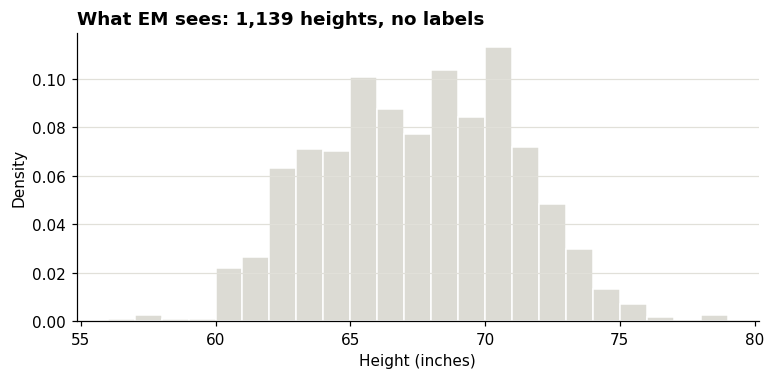

In [21]:
data = pd.read_csv("data/GaltonFamilies.csv")

children = data["childHeight"]
fathers = data.drop_duplicates("family")["father"]     # each father once

heights = np.concatenate([children, fathers])          # one pile, no labels

# Real labels, kept out of the EM fitting steps
is_child = np.concatenate([np.full(len(children), True), np.full(len(fathers), False)])
is_male = np.concatenate([data["gender"] == "male", np.full(len(fathers), True)])

print(f"{len(children)} children + {len(fathers)} fathers = {len(heights)} heights")
fig = plots.plot_heights(heights)
fig.savefig("figures/1_all_heights.png", bbox_inches="tight")

## Step 1: The bell curve

How common is height $x$ in a group with mean $\mu$ and variance $\sigma^2$? The bell curve answers that:

$$\mathcal{N}(x \mid \mu, \sigma^2) = \frac{1}{\sqrt{2\pi\sigma^2}}\; e^{-\frac{(x-\mu)^2}{2\sigma^2}}$$

Close to the mean → high value (common). Far from the mean → low value (rare).

In [22]:
def bell_curve(x, mean, var):
    """How common height x is in a group with this mean and variance."""
    return np.exp(-(x - mean) ** 2 / (2 * var)) / np.sqrt(2 * np.pi * var)

## Step 2: The E-step (give every person a percentage)

Remember the party example: to decide if someone is a child or a father, we need **two ingredients**:
1. how **common** that height is in each group → `bell_curve(...)`
2. how **big** each group is → `share`

Multiply them to get each group's **score**. The percentage is that group's score divided by the total:

$$P(\text{child} \mid x) = \frac{\pi_\text{child}\,\mathcal{N}(x \mid \mu_\text{child}, \sigma^2_\text{child})}{\pi_\text{child}\,\mathcal{N}(x \mid \mu_\text{child}, \sigma^2_\text{child}) + \pi_\text{father}\,\mathcal{N}(x \mid \mu_\text{father}, \sigma^2_\text{father})}$$

This is Bayes' rule. $P(\text{father} \mid x)$ is simply $1 - P(\text{child} \mid x)$.

In [23]:
def score(x, group):
    """Ingredient 1 x ingredient 2: the group's share x how common x is in the group."""
    return group["share"] * bell_curve(x, group["mean"], group["var"])


def e_step(heights, child, father):
    """For every height: the probability (0 to 1) that it belongs to the child group."""
    child_score = score(heights, child)
    father_score = score(heights, father)
    return child_score / (child_score + father_score)

## Step 3: The M-step (update the group estimates)

Now we recalculate each group's mean, variance and share. We don't know who belongs where, so **each person counts by their percentage**, exactly like our hand example (64 counted 90% toward the child hill):

$$\mu = \frac{\sum_i w_i\, x_i}{\sum_i w_i} \qquad \sigma^2 = \frac{\sum_i w_i\,(x_i - \mu)^2}{\sum_i w_i} \qquad \pi = \frac{\sum_i w_i}{n}$$

where $w_i$ is person $i$'s percentage for that group. These are the normal mean, variance and share, just weighted. One function does it for both groups:

In [24]:
def weighted_group(heights, weights):
    """Mean, variance and share of a group where each person counts by their weight (0 to 1)."""
    total = weights.sum()
    mean = (weights * heights).sum() / total
    var = (weights * (heights - mean) ** 2).sum() / total
    share = total / len(heights)
    return {"mean": mean, "var": var, "share": share}


def m_step(heights, p_child):
    """New child and father groups. Father percentages are 1 - child percentages."""
    child = weighted_group(heights, p_child)
    father = weighted_group(heights, 1 - p_child)
    return child, father

**Check against our hand example:** 4 people (62, 64, 70, 72) with child percentages 100%, 90%, 10%, 0%. By hand we got a child mean of **63.3** and a father mean of **70.7**.

In [25]:
example_heights = np.array([62, 64, 70, 72])
example_p_child = np.array([1.0, 0.9, 0.1, 0.0])

example_child, example_father = m_step(example_heights, example_p_child)
print(f"Child mean:  {example_child['mean']:.1f}")
print(f"Father mean: {example_father['mean']:.1f}")

Child mean:  63.3
Father mean: 70.7


## Step 4: The score that tells us when to stop (log-likelihood)

The **log-likelihood** measures how well the two Gaussian groups explain the observed heights. A higher value means a better fit:

$$\log L = \sum_{i=1}^{n} \log\big(\text{child score}(x_i) + \text{father score}(x_i)\big)$$

With the standard EM updates used here, the log-likelihood should stay the same or increase at each full iteration. We stop when its improvement is less than 0.000001. The parameter estimates may still change slightly.

In [26]:
def log_likelihood(heights, child, father):
    """How well the two hills explain all the heights (higher = better)."""
    return np.log(score(heights, child) + score(heights, father)).sum()

## Step 5: The starting guess (iteration 0)

EM needs a first guess. We use the naive method the assignment asks about: **draw a line at the overall average height**, call everyone below it "child" and everyone above it "father".

That is just an M-step where everyone is 100% one group or 100% the other, so we reuse `m_step`. This way, **iteration 0 of our table is the naive answer**, and the table shows how EM improves on it.

In [27]:
def naive_split(heights):
    """Line at the overall average: below = child (weight 1), above = father (weight 0)."""
    below_line = (heights < heights.mean()).astype(float)
    return m_step(heights, below_line)

## Step 6: Run EM

Repeat E-step → M-step, and keep a record of every iteration for the table.

In [28]:
def run_em(heights, child, father, tolerance=1e-6, max_iterations=5000):
    """Repeat E-step and M-step until the log-likelihood stops improving.
    Returns the history: a list of (child, father, log_likelihood), one per iteration."""
    history = [(child, father, log_likelihood(heights, child, father))]   # iteration 0

    for _ in range(max_iterations):
        p_child = e_step(heights, child, father)       # E-step
        child, father = m_step(heights, p_child)       # M-step
        new_score = log_likelihood(heights, child, father)

        old_score = history[-1][2]
        if new_score < old_score - 1e-9:
            raise ValueError("Log-likelihood went down. EM never does this, so there is a bug.")
        history.append((child, father, new_score))

        if new_score - old_score < tolerance:          # barely improved: stop
            break
    return history


start_child, start_father = naive_split(heights)
history = run_em(heights, start_child, start_father)
child, father, final_score = history[-1]

print(f"EM stopped after {len(history) - 1} iterations")

EM stopped after 309 iterations


## Step 7: The tracking table

Iteration 0 (the naive split), iterations 1 and 2, and the final one.

In [29]:
def tracking_table(history):
    rows = []
    for iteration, (c, f, ll) in enumerate(history):
        rows.append({
            "Iteration": iteration,
            "μ1 (Child)": c["mean"], "μ2 (Father)": f["mean"],
            "σ²1": c["var"], "σ²2": f["var"],
            "π1": c["share"], "π2": f["share"],
            "Log-likelihood": ll,
        })
    return pd.DataFrame(rows).set_index("Iteration")


table = tracking_table(history)
table.iloc[[0, 1, 2, -1]]

,μ1 (Child),μ2 (Father),σ²1,σ²2,π1,π2,Log-likelihood
Iteration,,,,,,,
0,64.2598,70.2147,4.1428,3.5711,0.5048,0.4952,-3071.1165
1,64.3784,70.0758,4.9168,4.2979,0.5033,0.4967,-3053.5777
2,64.4368,69.9988,5.3058,4.6724,0.5017,0.4983,-3049.7088
309,64.1772,69.5186,5.3024,6.0410,0.4325,0.5675,-3046.9895


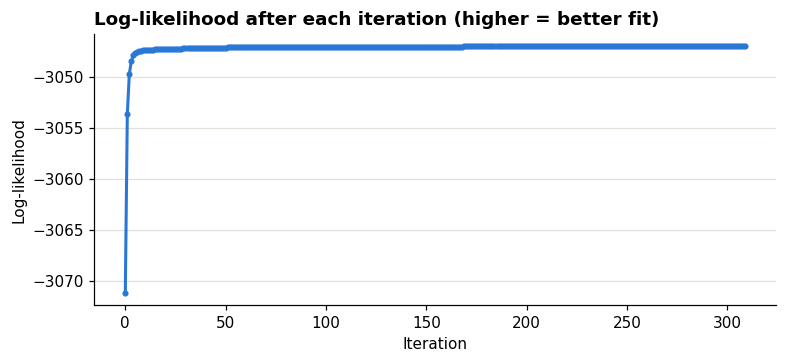

In [30]:
fig = plots.plot_log_likelihood(table["Log-likelihood"].to_numpy())
fig.savefig("figures/2_log_likelihood.png", bbox_inches="tight")

The log-likelihood improves most during the first few iterations, then changes by smaller amounts. The model takes many iterations to converge with this start and tolerance. The overlap between the groups is one reason the estimates change gradually.

**How the fitted curves change:**

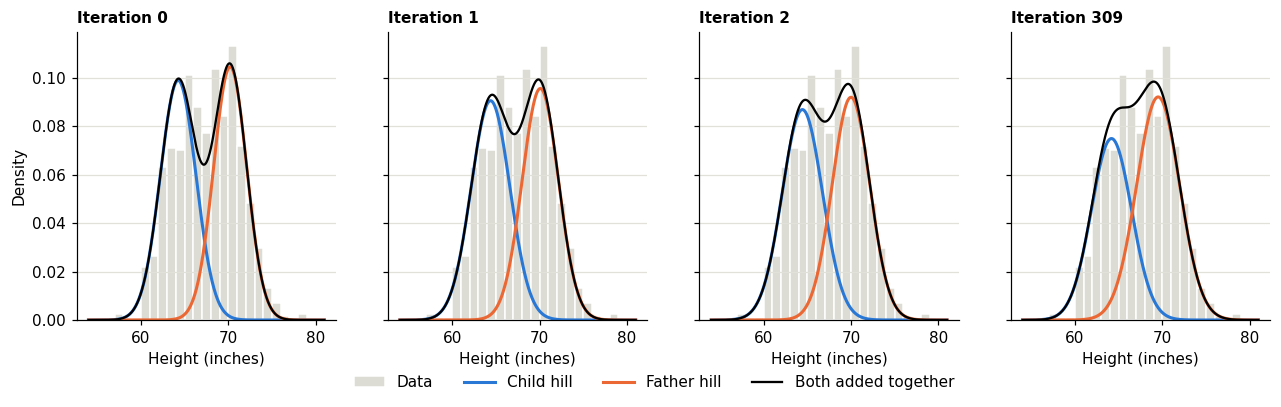

In [31]:
grid = np.arange(54, 81, 0.01)   # every height from 54 to 81 inches, in steps of 0.01

fig, axes = plt.subplots(1, 4, figsize=(14, 3.4), sharey=True)
for ax, i in zip(axes, [0, 1, 2, len(history) - 1]):
    c, f, ll = history[i]
    plots.plot_fit(ax, heights, grid, score(grid, c), score(grid, f), f"Iteration {i}")
axes[0].set_ylabel("Density")
fig.legend(*axes[0].get_legend_handles_labels(), loc="upper center", bbox_to_anchor=(0.5, 0), ncol=4)
fig.savefig("figures/3_hills_moving.png", bbox_inches="tight")

## Step 8: Why not just draw a line at the global mean?

**Because:**
1. A height just above the cutoff is assigned completely to one side, and one just below it to the other. EM gives heights near the overlap a probability for each group.
2. In our fitted model, the probability is 50/50 at about 66.54 inches. The global mean is 67.21 inches. That 50/50 point depends on the groups' shares and spreads, so it does not have to equal the overall mean.
3. In this dataset, the naive split gives smaller variances than the summaries calculated using the real sex labels. The table shows the values.
4. The simple split makes one cut and stops. Starting from that split, EM updates the estimates; in this run, the log-likelihood rises from about −3071 to −3047.

The table compares the naive split (iteration 0) with the fitted model. For the actual rows, we use the real labels to calculate height summaries by sex, then compare them with the model assignments in Step 9. There are no mothers in this pile: the female group is daughters, and the male group is sons plus fathers.

In [32]:
actual_female = weighted_group(heights, (~is_male).astype(float))   # same function, 0/1 weights
actual_male = weighted_group(heights, is_male.astype(float))

pd.DataFrame({
    "Naive split: child": start_child, "Naive split: father": start_father,
    "EM: child": child, "EM: father": father,
    "Actual: daughters": actual_female, "Actual: sons + fathers": actual_male,
}).T

,mean,var,share
Naive split: child,64.2598,4.1428,0.5048
Naive split: father,70.2147,3.5711,0.4952
EM: child,64.1772,5.3024,0.4325
EM: father,69.5186,6.0410,0.5675
Actual: daughters,64.1040,5.5368,0.3977
Actual: sons + fathers,69.2586,6.9027,0.6023


Global-mean line: 67.21 in
EM's 50/50 line:  66.54 in
Log-likelihood: naive -3071.12  ->  EM -3046.99


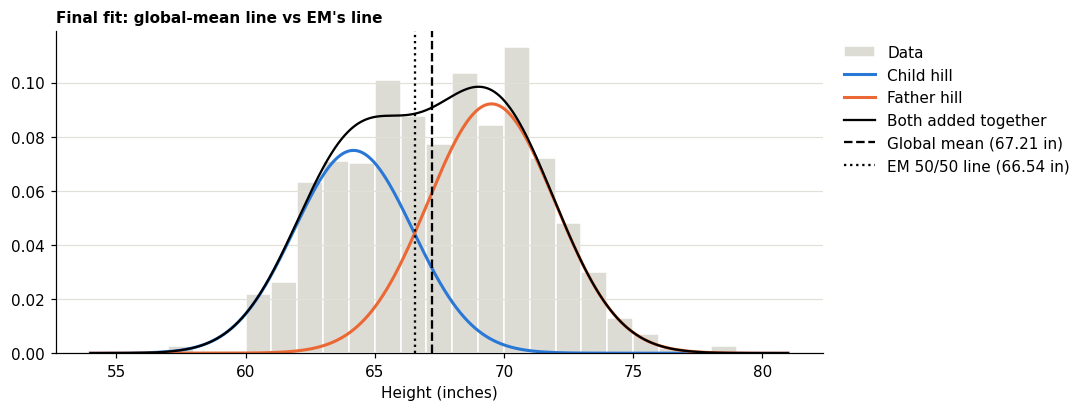

In [33]:
p_child_on_grid = e_step(grid, child, father)
boundary = grid[np.argmin(np.abs(p_child_on_grid - 0.5))]    # where it's 50/50

print(f"Global-mean line: {heights.mean():.2f} in")
print(f"EM's 50/50 line:  {boundary:.2f} in")
print(f"Log-likelihood: naive {history[0][2]:.2f}  ->  EM {final_score:.2f}")

fig, ax = plt.subplots(figsize=(9, 3.8))
plots.plot_fit(ax, heights, grid, score(grid, child), score(grid, father), "Final fit: global-mean line vs EM's line",
               lines={f"Global mean ({heights.mean():.2f} in)": heights.mean(),
                      f"EM 50/50 line ({boundary:.2f} in)": boundary})
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1))
fig.savefig("figures/4_final_fit.png", bbox_inches="tight")

## Step 9: Comparing the fitted groups with the real labels

We assign each height to the fitted group with the higher probability, then compare those assignments with the real labels.

In [34]:
em_says_child = e_step(heights, child, father) > 0.5

print(f"Child vs father: EM is right {np.mean(em_says_child == is_child):.1%} of the time")
print(f"(Always guessing 'child' would be right {np.mean(is_child):.1%} of the time)")
print(f"Female vs male:  EM is right {np.mean(em_says_child == ~is_male):.1%} of the time")

who = np.where(is_child, np.where(is_male, "Son", "Daughter"), "Father")
pd.crosstab(who, np.where(em_says_child, "EM says: Child", "EM says: Father"),
            rownames=["Real person"], colnames=[""])

Child vs father: EM is right 56.5% of the time
(Always guessing 'child' would be right 82.0% of the time)
Female vs male:  EM is right 84.7% of the time


,EM says: Child,EM says: Father
Real person,,
Daughter,392,61
Father,33,172
Son,80,401


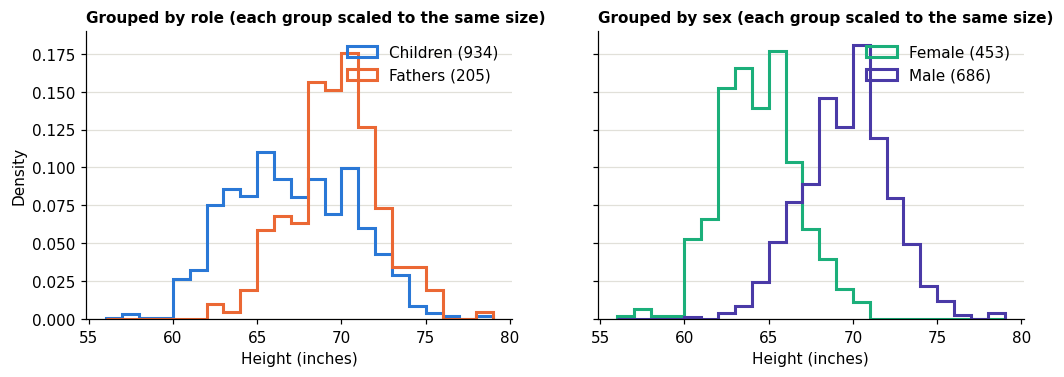

In [35]:
fig = plots.plot_true_groups(heights, is_child, is_male)
fig.savefig("figures/5_true_groups.png", bbox_inches="tight")

**EM does not use the sex or family-role labels while fitting.** After fitting, we compared its assignments with the real labels. In this run, the two groups matched sex better than parent versus child. Galton's children are adults, so sons have heights close to fathers, while daughters are shorter. The plots compare the groups by role and by sex.

This result depends on the data and the starting values. It shows that, for this run, height alone did not reliably separate fathers from their adult children.

## Step 10: Live demo (classify any height)

The probability for one new height is just the E-step on that one height.

,P(Child),P(Father)
Height (in),,
60,0.9965,0.0035
62,0.9825,0.0175
64,0.9098,0.0902
66,0.6236,0.3764
67,0.3934,0.6066
68,0.1988,0.8012
70,0.0328,0.9672
72,0.0042,0.9958
76,0.0000,1.0000


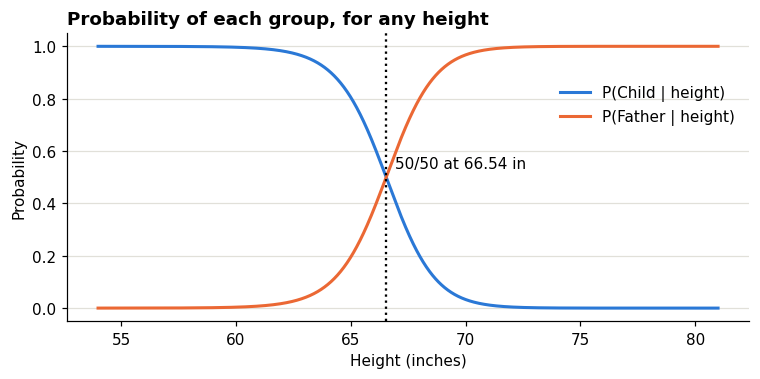

In [36]:
fig = plots.plot_child_probability(grid, p_child_on_grid, boundary)
fig.savefig("figures/6_child_probability.png", bbox_inches="tight")

examples = np.array([60, 62, 64, 66, 67, 68, 70, 72, 76])
pd.DataFrame({"P(Child)": e_step(examples, child, father),
              "P(Father)": 1 - e_step(examples, child, father)},
             index=pd.Index(examples, name="Height (in)"))

In [37]:
def classify(height, unit="in"):
    """Print P(Child) and P(Father) for one height."""
    if unit == "cm":
        height = height / 2.54                # convert cm to inches
    p_child = e_step(height, child, father)
    print(f"Height: {height:.2f} inches")
    print(f"  P(Child  | height) = {p_child:.4f}")
    print(f"  P(Father | height) = {1 - p_child:.4f}")
    print("  Most likely:", "Child" if p_child > 0.5 else "Father")

**Enter the coach's height below and run the cell** (use `unit="cm"` for centimetres). The printed probabilities are for the model's shorter and taller fitted groups, labelled Child and Father here. They do not reliably establish the person's actual family role for this dataset.

In [38]:
classify(68, unit="in")

Height: 68.00 inches
  P(Child  | height) = 0.1988
  P(Father | height) = 0.8012
  Most likely: Father


## Summary

- **E-step:** calculate each height's probability for each fitted group.
- **M-step:** recalculate the groups' means, variances, and shares using those probabilities as weights.
- **Stopping:** stop when the log-likelihood improvement is below 0.000001.
- **Global-mean split:** it assigns each height to one side of a cutoff. Its estimates differ from the EM estimates in this dataset.
- **Checking the result:** compare the fitted groups with the real labels afterward. In this run, they matched sex more closely than family role.